In [1]:
# 1. Install the emoji library (needed for cleaning)
!pip install emoji

import pandas as pd
import emoji
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 9.8 MB/s eta 0:00:00


In [2]:
from google.colab import files
import pandas as pd
import io
uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))
print(f"Successfully uploaded: {filename}")
df.head()

Saving Instagram - Sheet1.csv to Instagram - Sheet1.csv
Successfully uploaded: Instagram - Sheet1.csv


,context,comment,label
0,A child singing japanese song,His voice is close to perfection. Dont need ly...,Positive
1,A child singing japanese song,Song Name: A Town With An Ocean View.,Neutral
2,A child singing japanese song,"I felt peace, his voice is just like an angel’s🌸🤕",Positive
3,A child singing japanese song,I wish this was on Spotify,Positive
4,A child singing japanese song,please like so i can comeback for this masterp...,Positive


In [3]:
print(len(df))

107


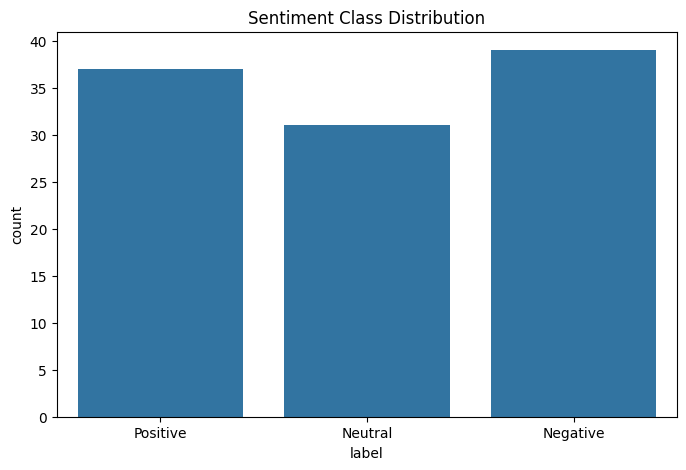

In [4]:
df['label'].value_counts(normalize=True)

# Visualize the distribution
plt.figure(figsize=(8, 5))
sns.countplot(x='label', data=df)
plt.title('Sentiment Class Distribution')
plt.show()

In [5]:
# ==========================================
# PART 1: THE CLEANING FUNCTION
# (Run this on your DataFrame columns)
# ==========================================
def clean_text(text):
    # 1. Ensure it's a string (handles empty cells)
    text = str(text)

    # 2. Lowercase: Normalizes "Bad" and "bad" to the same word
    text = text.lower()

    # 3. Demojize: Converts emojis to text (e.g., 😡 -> :pouting_face:)
    text = emoji.demojize(text)

    # 4. Spacing: Replaces ":" with space so "face" doesn't get stuck to "pouting"
    text = text.replace(":", " ")

    # 5. Fix Elongation: Reduces "sooooo" to "soo" (max 2 repeated chars)
    #    (Crucial for social media slang)
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)

    return text

# Apply it
df['clean_comment'] = df['comment'].apply(clean_text)

# Combine Context + Comment
df['combined_text'] = df['context'] + " " + df['clean_comment']

# ==========================================
# PART 2: THE MODEL CONFIGURATION
# (This preserves punctuation like ! and ?)
# ==========================================

# Regex Explanation:
# \w+  -> Matches any word (letters/numbers)
# |    -> OR
# [!?] -> Matches ! or ? explicitly as their own tokens
custom_token_pattern = r'\w+|[!?]'

In [6]:
# ==========================================
# 3. MODEL TRAINING
# ==========================================
# Split Data (75% Train, 25% Test)
X_train, X_test, y_train, y_test = train_test_split(
    df['combined_text'],
    df['label'],
    test_size=0.25,
    random_state=42,
    stratify=df['label']
)

# --- DEBUGGING PRINT ---
print(f"🎓 Training Rows: {len(X_train)} (75%)")
print(f"📝 Test Rows (Heatmap): {len(X_test)} (25%)")
# -----------------------

🎓 Training Rows: 80 (75%)
📝 Test Rows (Heatmap): 27 (25%)


In [7]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
# Custom pattern:
# 1. \w+  -> Matches words
# 2. |    -> OR
# 3. [!?] -> Matches exclamation and question marks
custom_token_pattern = r'\w+|[!?]'

C = CountVectorizer(
    lowercase=True,
    token_pattern=custom_token_pattern,  # <--- Forces it to count ! and ?
    ngram_range=(1, 2)  # <--- Look at 1 word AND pairs of 2 words
)

# Example Proof
text = ["I loved it!!!", "Really?", "I don't think so."]
vector = C.fit_transform(text)

print("Vocabulary:", C.get_feature_names_out())

Vocabulary: ['!' '! !' '?' 'don' 'don t' 'i' 'i don' 'i loved' 'it' 'it !' 'loved'
 'loved it' 'really' 'really ?' 'so' 't' 't think' 'think' 'think so']



--- Classification Report (Logistic Regression) ---
              precision    recall  f1-score   support

    Negative       0.75      0.90      0.82        10
     Neutral       0.75      0.75      0.75         8
    Positive       0.86      0.67      0.75         9

    accuracy                           0.78        27
   macro avg       0.79      0.77      0.77        27
weighted avg       0.79      0.78      0.78        27



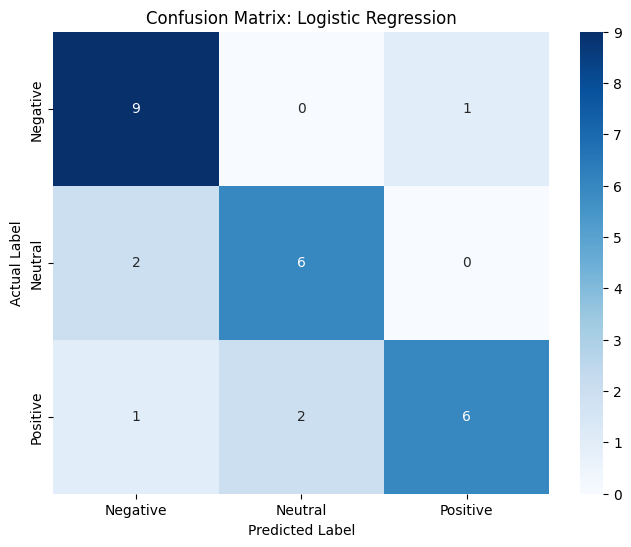

In [9]:
lr_model = make_pipeline(
    C,
    LogisticRegression(class_weight='balanced', max_iter=1000)
)

lr_model.fit(X_train, y_train)

# ==========================================
# 4. EVALUATION
# ==========================================
y_pred_lr = lr_model.predict(X_test)

labels = ['Negative', 'Neutral', 'Positive']
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=labels)

print("\n--- Classification Report (Logistic Regression) ---")
print(classification_report(y_test, y_pred_lr))

# Plotting
plt.figure(figsize=(8, 6))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.title('Confusion Matrix: Logistic Regression')
plt.show()

Training SVC ...

--- SVC Performance ---
              precision    recall  f1-score   support

    negative       0.90      0.90      0.90        10
     neutral       0.60      0.75      0.67         8
    positive       0.86      0.67      0.75         9

    accuracy                           0.78        27
   macro avg       0.79      0.77      0.77        27
weighted avg       0.80      0.78      0.78        27



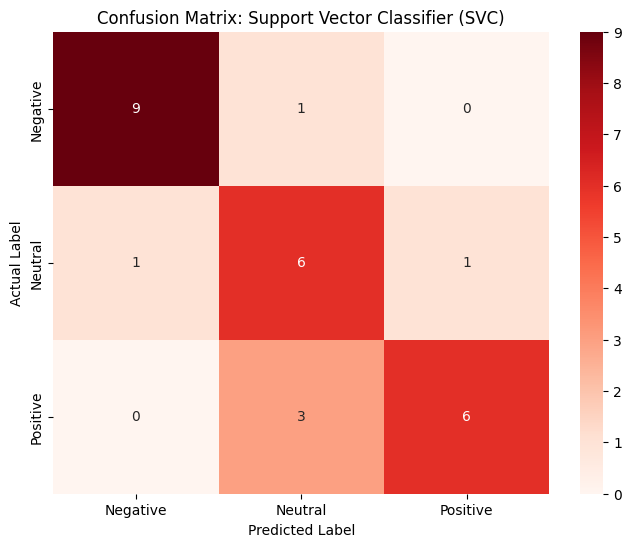

In [10]:
from sklearn.svm import LinearSVC

# Define the pipeline for SVC
svc_model = Pipeline([
    ('C', CountVectorizer(max_features=5000)),
    ('classifier', LinearSVC(random_state=42, dual=False))
])

# Train and evaluate
print("Training SVC ...")
svc_model.fit(X_train, y_train)
y_pred_svc = svc_model.predict(X_test)
print("\n--- SVC Performance ---")
print(classification_report(y_test, y_pred_svc, target_names=['negative', 'neutral', 'positive']))

# 5. PLOT THE HEATMAP
# Define the order explicitly so the chart makes sense (Bad -> Neutral -> Good)
labels = ['Negative', 'Neutral', 'Positive']

# Create the confusion matrix
cm_svc = confusion_matrix(y_test, y_pred_svc, labels=labels)

# Plot using Seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(cm_svc, annot=True, fmt='d', cmap='Reds',
            xticklabels=labels, yticklabels=labels)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix: Support Vector Classifier (SVC)')
plt.show()

Label Mapping: {'Negative': np.int64(0), 'Neutral': np.int64(1), 'Positive': np.int64(2)}
Training XGBoost...

--- XGBoost Performance ---
              precision    recall  f1-score   support

    Negative       0.60      0.60      0.60        10
     Neutral       0.62      0.62      0.62         8
    Positive       0.44      0.44      0.44         9

    accuracy                           0.56        27
   macro avg       0.56      0.56      0.56        27
weighted avg       0.56      0.56      0.56        27



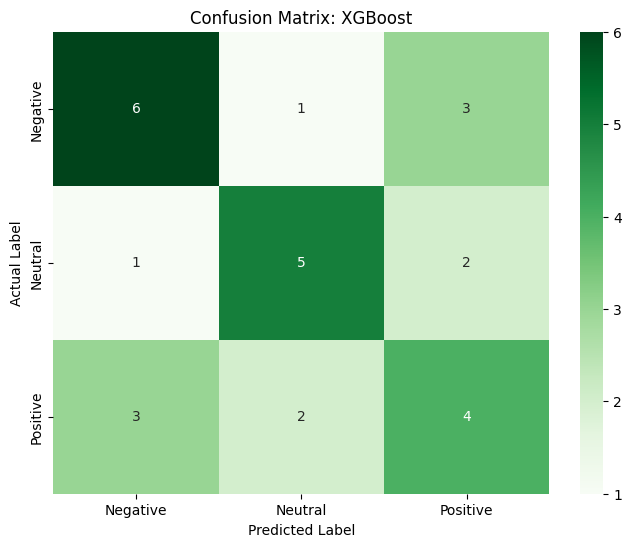

In [11]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

# ==========================================
# 1. PREPARE LABELS (XGBoost Specific Requirement)
# ==========================================
# XGBoost requires numbers (0, 1, 2), not strings ("Negative", etc.)
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

# Print mapping so you know which number is which
# e.g., 0=Negative, 1=Neutral, 2=Positive
label_mapping = dict(zip(le.classes_, le.transform(le.classes_)))
print(f"Label Mapping: {label_mapping}")

# ==========================================
# 2. DEFINE PIPELINE
# ==========================================
xgb_model = Pipeline([
    # Consistent Vectorizer ('C')
    ('C', CountVectorizer(
        max_features=5000
    )),
    ('classifier', XGBClassifier(
        random_state=42,
        n_jobs=-1,
        n_estimators=50,      # <--- We set this to 50 trees
        learning_rate=0.1,    # <--- Slightly lower learning rate (default is 0.3)
        max_depth=3           # <--- Keep trees shallow (3 decisions max) to prevent overfitting
        ))
])

# ==========================================
# 3. TRAIN & PREDICT
# ==========================================
print("Training XGBoost...")
xgb_model.fit(X_train, y_train_enc)

y_pred_xgb = xgb_model.predict(X_test)

# ==========================================
# 4. EVALUATION & HEATMAP
# ==========================================
# Convert numbers back to names for the report/plot
target_names = le.classes_ # ['Negative', 'Neutral', 'Positive']

print("\n--- XGBoost Performance ---")
print(classification_report(y_test_enc, y_pred_xgb, target_names=target_names))

# Confusion Matrix
cm_xgb = confusion_matrix(y_test_enc, y_pred_xgb)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Greens',
            xticklabels=target_names, yticklabels=target_names)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix: XGBoost')
plt.show()

Training Naive Bayes...

--- Naive Bayes Performance ---
              precision    recall  f1-score   support

    Negative       0.56      1.00      0.71        10
     Neutral       1.00      0.50      0.67         8
    Positive       1.00      0.56      0.71         9

    accuracy                           0.70        27
   macro avg       0.85      0.69      0.70        27
weighted avg       0.84      0.70      0.70        27



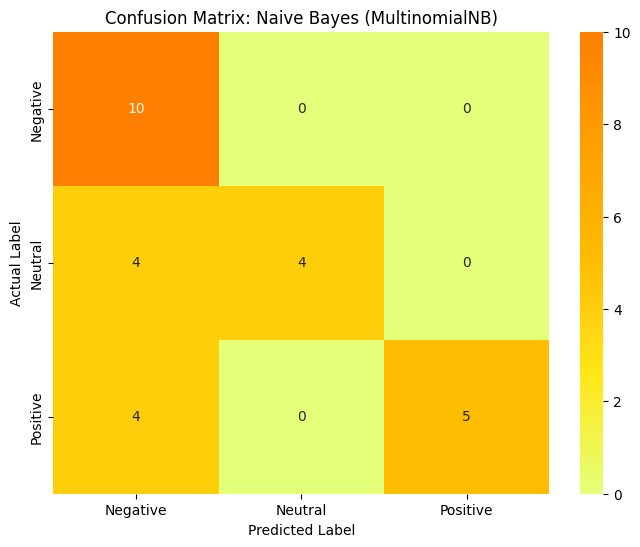

In [12]:
from sklearn.naive_bayes import MultinomialNB

# 1. Define the Pipeline
nb_model = Pipeline([
    # Consistent Vectorizer settings
    ('C', CountVectorizer(
        max_features=5000)),
    # Naive Bayes Classifier
    ('classifier', MultinomialNB())
])

# 2. Train
print("Training Naive Bayes...")
nb_model.fit(X_train, y_train)

# 3. Predict
y_pred_nb = nb_model.predict(X_test)

# 4. Evaluation
print("\n--- Naive Bayes Performance ---")
print(classification_report(y_test, y_pred_nb))

# 5. Plot Heatmap
labels = ['Negative', 'Neutral', 'Positive']
cm_nb = confusion_matrix(y_test, y_pred_nb, labels=labels)

plt.figure(figsize=(8, 6))
# Using 'Oranges' to distinguish from the other models
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Wistia',
            xticklabels=labels, yticklabels=labels)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix: Naive Bayes (MultinomialNB)')
plt.show()

In [13]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import torch

# Calculate the weights
class_labels = np.unique(y_train)
class_weights = compute_class_weight(class_weight='balanced', classes=class_labels, y=y_train)

# Convert to a PyTorch tensor
weights = torch.tensor(class_weights, dtype=torch.float).to('cuda')
weights

tensor([0.9195, 1.1594, 0.9524], device='cuda:0')

# ---------------------- Transformer(DistilBert) ------------------------

In [14]:
from transformers import AutoTokenizer
from datasets import Dataset

# 1. LABEL ENCODING (Crucial Step for DistilBERT)
# Convert "Negative" -> 0, "Neutral" -> 1, "Positive" -> 2
label_map = {'Negative': 0, 'Neutral': 1, 'Positive': 2}

# Helper function to convert a list of strings to numbers
def encode_labels(labels):
    return [label_map[label] for label in labels]

# Apply encoding
y_train_encoded = encode_labels(y_train)
y_test_encoded = encode_labels(y_test)

# 2. Load the Tokenizer
model_name = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

# 3. Tokenize Text
# Convert pandas Series to list (list(X_train)) ensures the tokenizer accepts it
train_encodings = tokenizer(list(X_train), truncation=True, padding=True, max_length=128)
test_encodings = tokenizer(list(X_test), truncation=True, padding=True, max_length=128)

# 4. Create Hugging Face Dataset objects
# We pass the ENCODED numeric labels here
train_dataset = Dataset.from_dict({
    'input_ids': train_encodings['input_ids'],
    'attention_mask': train_encodings['attention_mask'],
    'labels': y_train_encoded
})

test_dataset = Dataset.from_dict({
    'input_ids': test_encodings['input_ids'],
    'attention_mask': test_encodings['attention_mask'],
    'labels': y_test_encoded
})

print("✅ Data prepared for DistilBERT!")
print(f"Example Label: '{y_train.iloc[0]}' converted to {y_train_encoded[0]}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

✅ Data prepared for DistilBERT!
Example Label: 'Negative' converted to 0


In [16]:
from transformers import Trainer
# This trainer overrides the standard loss function to use our weighted loss
class CustomTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get("labels")
        # forward pass
        outputs = model(**inputs)
        logits = outputs.get('logits')

        # compute custom loss using the calculated 'weights'
        loss_fct = torch.nn.CrossEntropyLoss(weight=weights)

        # Correctly reshape the logits tensor
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))

        return (loss, outputs) if return_outputs else loss

In [18]:
from transformers import AutoModelForSequenceClassification, Trainer, TrainingArguments
from sklearn.metrics import classification_report

# 1. Load the pre-trained DistilBERT model
# We tell it we have 3 labels (negative, neutral, positive)
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=3)

# 2. Define the training settings
# These are the hyperparameters for our fine-tuning process
training_args = TrainingArguments(
    output_dir='./results',          # directory to save model checkpoints
    num_train_epochs=2,              # number of training epochs
    per_device_train_batch_size=16,  # batch size for training
    per_device_eval_batch_size=64,   # batch size for evaluation
    warmup_steps=50,                # number of warmup steps for learning rate scheduler
    weight_decay=0.01,               # strength of weight decay
    logging_dir='./logs',            # directory for storing logs
    logging_steps=10,
)

# 3. Create the Trainer object
# This object brings together the model, settings, and datasets
trainer = CustomTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset
)

# 4. Fine-tune the model!
# This single command handles the entire training process
print("Fine-tuning the Transformer model...")
trainer.train()
print("Training complete.")

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Fine-tuning the Transformer model...


/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: Logging into wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: You can find your API key in your browser here: https://wandb.ai/authorize?ref=models
wandb: Paste an API key from your profile and hit enter:

 ··········


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: mandiramajhi7 (mandiramajhi7-ai) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Step,Training Loss
10,1.101700


Training complete.


Predicting with DistilBERT...



--- Weighted Transformer Model Performance ---
              precision    recall  f1-score   support

    Negative       0.35      0.60      0.44        10
     Neutral       0.00      0.00      0.00         8
    Positive       0.50      0.33      0.40         9

    accuracy                           0.33        27
   macro avg       0.28      0.31      0.28        27
weighted avg       0.30      0.33      0.30        27



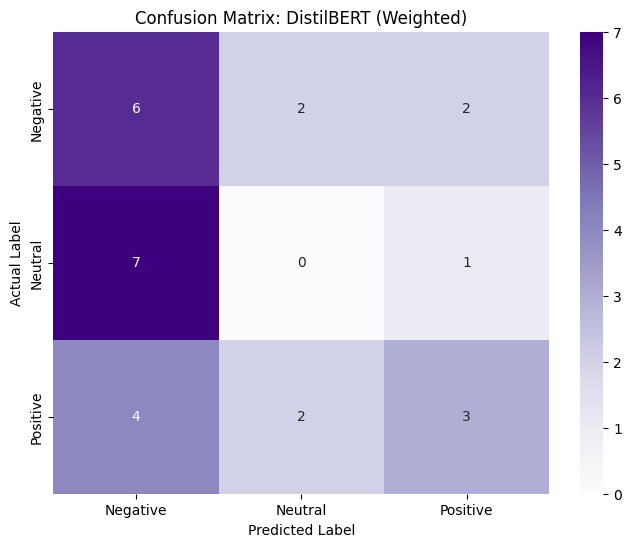

In [21]:
# 1. Get Predictions
print("Predicting with DistilBERT...")
predictions = trainer.predict(test_dataset)

# Convert logic scores (logits) to actual class numbers (0, 1, 2)
y_pred_transformer = np.argmax(predictions.predictions, axis=-1)

# 2. Define Names for the Report/Plot
target_names = ['Negative', 'Neutral', 'Positive']

# 3. Print Classification Report
# Note: We use y_test_encoded (numbers) to match y_pred_transformer (numbers)
print("\n--- Weighted Transformer Model Performance ---")
print(classification_report(y_test_encoded, y_pred_transformer, target_names=target_names))

# 4. Generate Confusion Matrix
cm_transformer = confusion_matrix(y_test_encoded, y_pred_transformer)

# 5. Plot Heatmap
plt.figure(figsize=(8, 6))
# Using 'Purples' to represent the "Deep Learning" model
sns.heatmap(cm_transformer, annot=True, fmt='d', cmap='Purples',
            xticklabels=target_names, yticklabels=target_names)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix: DistilBERT (Weighted)')
plt.show()

In [26]:
# Initialize the results container
results_list = []

# ==========================================
# 1. LOGISTIC REGRESSION (Uses Text Labels)
# ==========================================
# Predict
y_pred_lr = lr_model.predict(X_test)
report_lr = classification_report(y_test, y_pred_lr, output_dict=True)

results_list.append({
    "Model": "Logistic Regression",
    "Weighted F1-Score": report_lr['weighted avg']['f1-score'],
    "Negative Recall": report_lr['Negative']['recall'],
    "Neutral Recall": report_lr['Neutral']['recall'],
    "Positive Recall": report_lr['Positive']['recall']
})

# ==========================================
# 2. LINEAR SVC (Uses Text Labels)
# ==========================================
y_pred_svc = svc_model.predict(X_test)
report_svc = classification_report(y_test, y_pred_svc, output_dict=True)

results_list.append({
    "Model": "Linear SVC",
    "Weighted F1-Score": report_svc['weighted avg']['f1-score'],
    "Negative Recall": report_svc['Negative']['recall'],
    "Neutral Recall": report_svc['Neutral']['recall'],
    "Positive Recall": report_svc['Positive']['recall']
})

# ==========================================
# 3. NAIVE BAYES (Uses Text Labels)
# ==========================================
y_pred_nb = nb_model.predict(X_test)
report_nb = classification_report(y_test, y_pred_nb, output_dict=True)

results_list.append({
    "Model": "Naive Bayes",
    "Weighted F1-Score": report_nb['weighted avg']['f1-score'],
    "Negative Recall": report_nb['Negative']['recall'],
    "Neutral Recall": report_nb['Neutral']['recall'],
    "Positive Recall": report_nb['Positive']['recall']
})

# ==========================================
# 4. XGBOOST (Uses Numeric Labels 0,1,2)
# ==========================================
# Note: XGBoost used y_test_enc (encoded labels)
# 0=Negative, 1=Neutral, 2=Positive
y_pred_xgb = xgb_model.predict(X_test)
report_xgb = classification_report(y_test_enc, y_pred_xgb, output_dict=True)

results_list.append({
    "Model": "XGBoost",
    "Weighted F1-Score": report_xgb['weighted avg']['f1-score'],
    "Negative Recall": report_xgb['0']['recall'],
    "Neutral Recall": report_xgb['1']['recall'],
    "Positive Recall": report_xgb['2']['recall']
})

# ==========================================
# 5. DISTILBERT (Uses Numeric Labels 0,1,2)
# ==========================================
# Note: DistilBERT used test_dataset and y_test_encoded
predictions = trainer.predict(test_dataset)
y_pred_transformer = np.argmax(predictions.predictions, axis=-1)
report_transformer = classification_report(y_test_encoded, y_pred_transformer, output_dict=True)

results_list.append({
    "Model": "DistilBERT",
    "Weighted F1-Score": report_transformer['weighted avg']['f1-score'],
    "Negative Recall": report_transformer['0']['recall'],
    "Neutral Recall": report_transformer['1']['recall'],
    "Positive Recall": report_transformer['2']['recall']
})

# ==========================================
# FINAL LEADERBOARD
# ==========================================
final_comparison_df = pd.DataFrame(results_list)

# Sorting by F1-Score to see the best overall performer
print("--- Final Model Comparison ---")
print(final_comparison_df.round(3).sort_values(by="Weighted F1-Score", ascending=False))

--- Final Model Comparison ---
                 Model  Weighted F1-Score  Negative Recall  Neutral Recall  \
1           Linear SVC              0.781              0.9           0.750   
0  Logistic Regression              0.775              0.9           0.750   
2          Naive Bayes              0.700              1.0           0.500   
3              XGBoost              0.556              0.6           0.625   
4           DistilBERT              0.298              0.6           0.000   

   Positive Recall  
1            0.667  
0            0.667  
2            0.556  
3            0.444  
4            0.333  


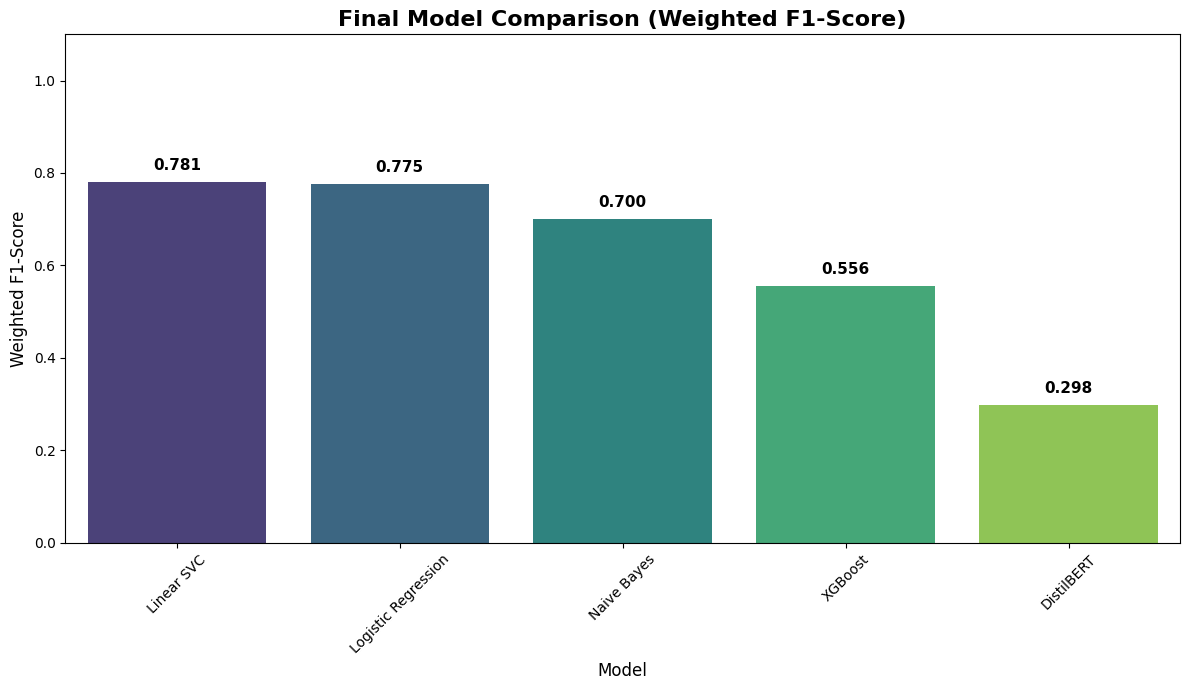

In [27]:

# Sort the data so the best model is on the left
plot_df = final_comparison_df.sort_values(by="Weighted F1-Score", ascending=False)

plt.figure(figsize=(12, 7))

# 1. Plot the Bar Chart
# Removed 'hue="Method"' because that column doesn't exist.
# Using 'hue="Model"' creates the colors based on the model name.
sns.barplot(
    data=plot_df,
    x="Model",
    y="Weighted F1-Score",
    hue="Model",
    palette="viridis", # Nice color scheme
    legend=False       # Hide legend since X-axis labels are clear enough
)

# 2. Add Titles and Labels
plt.title("Final Model Comparison (Weighted F1-Score)", fontsize=16, fontweight='bold')
plt.xlabel("Model", fontsize=12)
plt.ylabel("Weighted F1-Score", fontsize=12)
plt.xticks(rotation=45)
plt.ylim(0.0, 1.1)  # Set limit to 1.1 to make room for text labels

# 3. Add the exact numbers on top of each bar
for i, row in enumerate(plot_df.itertuples()):
    # row.Index is the dataframe index, row._2 is the F1-Score (based on column order)
    # Safer to lookup by name if column order changes, but iterating plot_df works:
    score = row._2  # Accessing 'Weighted F1-Score' by position or name
    # Note: namedtuples from itertuples use mangled names if they have spaces.
    # Let's use a standard zip approach for safety:

# Safer text labeling method:
for i, score in enumerate(plot_df["Weighted F1-Score"]):
    plt.text(i, score + 0.02, f"{score:.3f}", ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

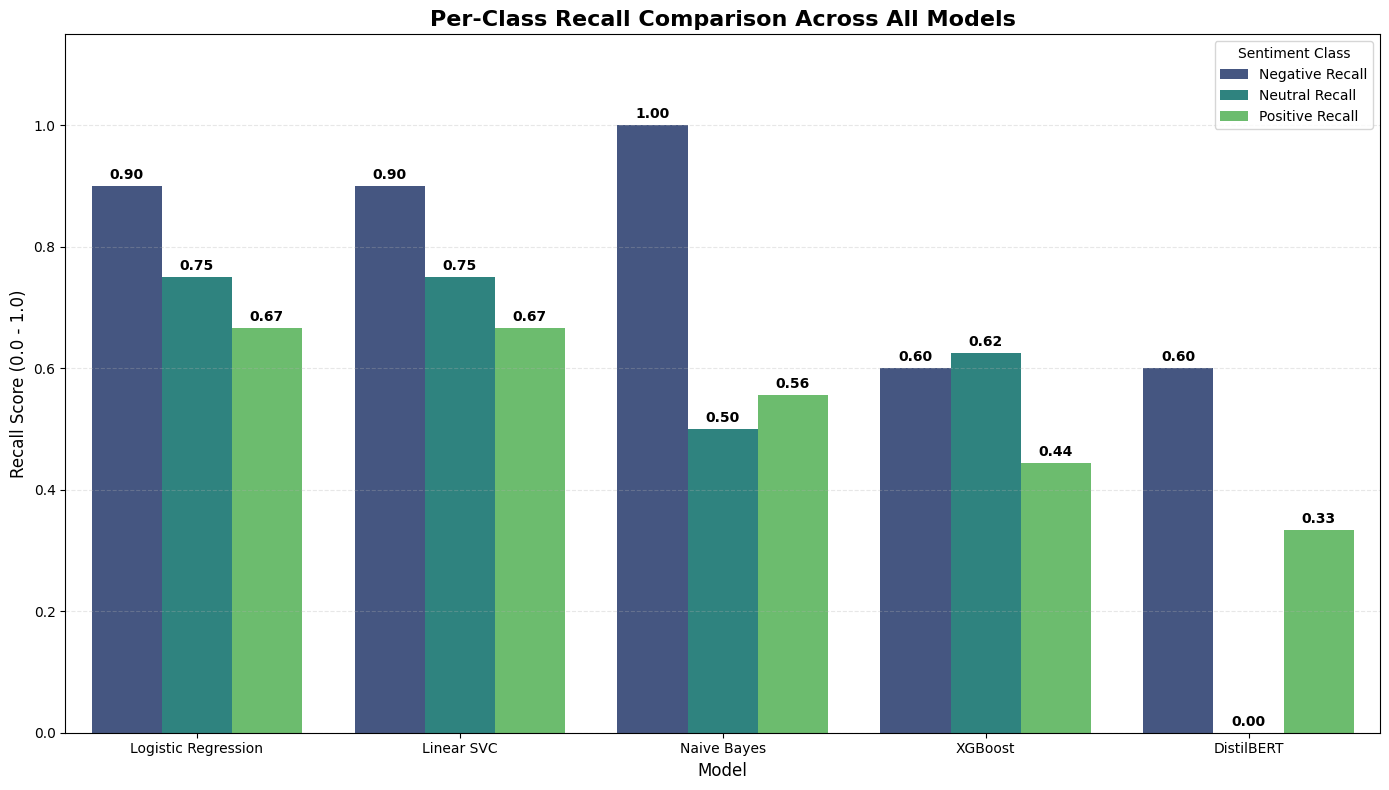

In [28]:
# 1. Melt the DataFrame
# This reshapes the data so we can plot multiple bars (one for each class) per model
plot_df = final_comparison_df.melt(
    id_vars=["Model"],
    value_vars=["Negative Recall", "Neutral Recall", "Positive Recall"],
    var_name="Class",
    value_name="Recall Score"
)

# 2. Setup the Plot
plt.figure(figsize=(14, 8))

# 3. Create the Grouped Bar Chart
ax = sns.barplot(
    data=plot_df,
    x="Model",
    y="Recall Score",
    hue="Class",
    palette="viridis"
)

# 4. Add Styling and Labels
plt.title("Per-Class Recall Comparison Across All Models", fontsize=16, fontweight='bold')
plt.xlabel("Model", fontsize=12)
plt.ylabel("Recall Score (0.0 - 1.0)", fontsize=12)
plt.ylim(0, 1.15) # Extra space at top for labels
plt.legend(title="Sentiment Class", loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.3)

# 5. Add Exact Numbers on Top of Bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3, fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()